In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [ ]:
import kagglehub
import os
import shutil
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
import lightgbm as lgb
import datetime as dt
import calendar,warnings,itertools,matplotlib,keras,shutil
import tensorflow as tf
import statsmodels.api as sm
from datetime import datetime
from sklearn.model_selection import train_test_split,cross_val_score, cross_val_predict
from sklearn import svm,metrics,tree,preprocessing,linear_model
from sklearn.preprocessing import MinMaxScaler,StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import Ridge,LinearRegression,LogisticRegression,ElasticNet, Lasso
from sklearn.ensemble import RandomForestRegressor,RandomForestClassifier, GradientBoostingRegressor,BaggingClassifier,ExtraTreesClassifier, StackingRegressor
from sklearn.metrics import accuracy_score,mean_squared_error,recall_score,confusion_matrix,f1_score,roc_curve, auc
from sklearn.datasets import load_iris,make_regression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.kernel_ridge import KernelRidge
from sklearn.svm import SVR
from keras import Sequential
from keras.layers import Dense
from IPython.core import display as ICD
#Hiding the warnings
warnings.filterwarnings('ignore')

In [ ]:
# Unduh dataset dari Kaggle
path = kagglehub.dataset_download("sergionefedov/inventory-and-stockout-optimization")

# Salin file CSV ke direktori saat ini
source_file = os.path.join(path, "inventory_optimization.csv")
if os.path.exists(source_file):
    shutil.copy(source_file, "inventory_optimization.csv")

100%|██████████| 2.51M/2.51M [00:00<00:00, 130MB/s]

Extracting files...


In [ ]:
df = pd.read_csv('inventory_optimization.csv')
df.head()

,sku_id,category,ignores_lead_time_variability,mean_daily_demand,sigma_daily_demand,demand_cv,mean_lead_time,sigma_lead_time,lead_time_cv,unit_cost,...,stockout_frequency,units_short,units_excess,holding_cost,shortage_cost,spoilage_cost,total_cost,optimal_service_level,service_level_gap,stockout_occurred
0,SKU000000,high_value,1,8.4,6.10,0.726,12.5,6.51,0.521,340.94,...,0.417,25.91,46.09,236.88,17594.70,0.00,17870.58,0.995,-0.095,1
1,SKU000001,perishable,1,9.9,4.49,0.454,17.8,10.39,0.584,15.95,...,0.250,9.83,34.80,13.43,175.37,222.02,499.82,0.988,-0.088,1
2,SKU000002,fast_mover,1,13.6,4.21,0.310,13.5,6.23,0.462,28.03,...,0.500,33.72,55.06,19.21,612.36,0.00,726.57,0.990,0.000,1
3,SKU000003,fast_mover,0,6.1,1.80,0.294,12.7,6.05,0.476,6.52,...,0.000,0.00,65.31,5.32,0.00,0.00,43.32,0.991,-0.091,0
4,SKU000004,seasonal,1,53.2,37.35,0.702,7.4,1.03,0.139,11.21,...,0.000,0.00,141.06,9.91,0.00,0.00,107.91,0.992,-0.092,0


In [ ]:
df.shape

(45000, 28)

In [ ]:
df.apply(lambda x: sum(x.isnull()))

,0
sku_id,0
category,0
ignores_lead_time_variability,0
mean_daily_demand,0
sigma_daily_demand,0
demand_cv,0
mean_lead_time,0
sigma_lead_time,0
lead_time_cv,0
unit_cost,0


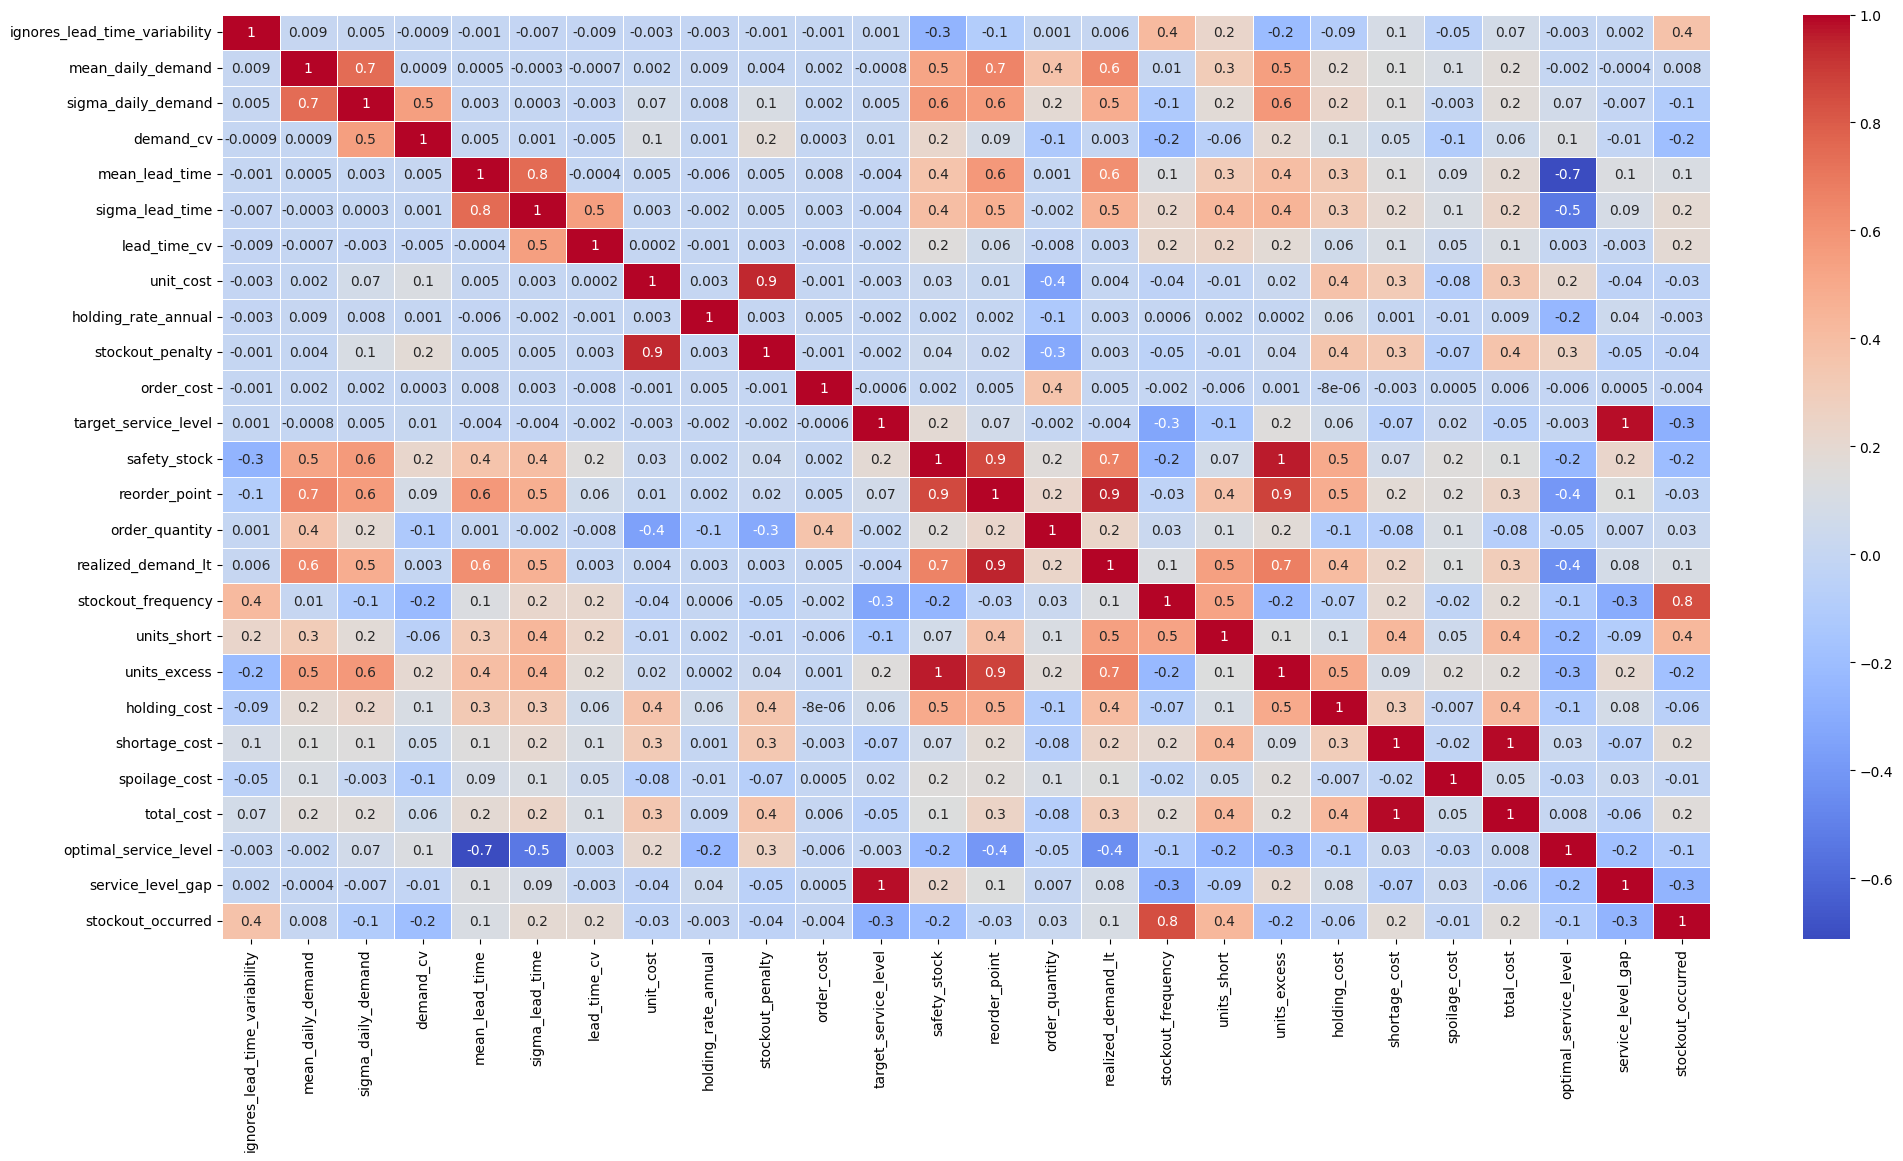

In [ ]:
fig, ax = plt.subplots(figsize=(24, 12))

# Hitung korelasi hanya untuk kolom numerik
corr_matrix = df.corr(numeric_only=True)

# Tampilkan heatmap
sns.heatmap(corr_matrix, annot=True, linewidths=0.5, fmt='.1g', cmap='coolwarm', ax=ax)

plt.show()

<Axes: title={'center': 'Daily Demand Each Category'}, xlabel='category'>

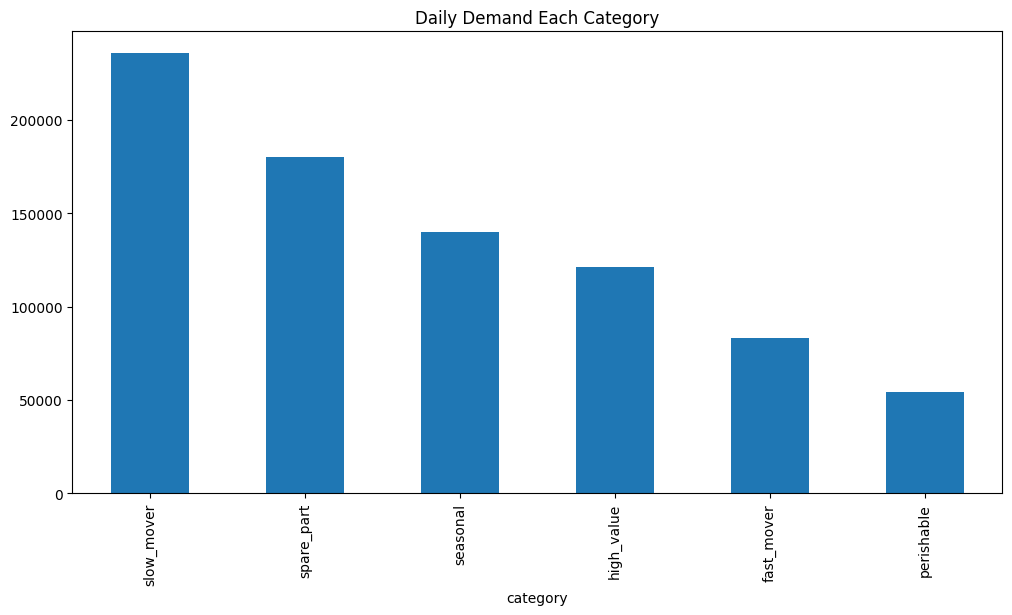

In [ ]:
category = df.groupby('category')
plt.figure(1)
category['sigma_daily_demand'].sum().sort_values(ascending=False).plot.bar(figsize=(12,6), title="Daily Demand Each Category")

In [ ]:
train_data=df.copy()

In [ ]:
x=train_data.loc[:, train_data.columns != 'sigma_daily_demand']
y=train_data['sigma_daily_demand']
x_train, x_test,y_train,y_test = train_test_split(x,y,test_size = 0.3, random_state = 42)

In [ ]:
# 1. Hapus ID dan lakukan One-Hot Encoding pada fitur string/kategori
X = train_data.drop(columns=['sku_id', 'sigma_daily_demand'])
X = pd.get_dummies(X, columns=['category'], drop_first=True)
y = train_data['sigma_daily_demand']

# 2. Split data
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# 3. Apply MinMaxScaler
scaler = MinMaxScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [ ]:
# List penampung hasil evaluasi
results = []

# Data Modelling
def regressionmodel(model, x_train, x_test, y_train, y_test):
    # Fit model
    model = model.fit(x_train, y_train)

    # Prediksi data test
    y_pred = model.predict(x_test)

    # Hitung metrik evaluasi
    mae = metrics.mean_absolute_error(y_test, y_pred)
    mse = metrics.mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = metrics.r2_score(y_test, y_pred)
    mape = metrics.mean_absolute_percentage_error(y_test, y_pred)

    # Hitung Adjusted R2
    n = len(y_test)
    p = x_test.shape[1] if hasattr(x_test, 'shape') else 1
    adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)

    # Print hasil
    print('Model parameter used are:', model)
    print("--------------------------------------------------")
    print("MAE of sales is         :", mae)
    print("MSE of sales is         :", mse)
    print("RMSE of sales is        :", rmse)
    print("R2 Score is             :", r2)
    print("Adjusted R2 Score is    :", adj_r2)
    print("MAPE of sales is        :", mape)
    print("--------------------------------------------------")

    # Simpan hasil ke dalam list
    results.append({
        'Regression Model': model,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'MAPE': mape,
        'R2 Score': r2,
        'Adjusted R2': adj_r2
    })


    return model

In [ ]:
model = Ridge(alpha=0.1)
regressionmodel(model, x_train, x_test, y_train, y_test)

Model parameter used are: Ridge(alpha=0.1)
--------------------------------------------------
MAE of sales is         : 4.114723039828885
MSE of sales is         : 41.92749353728666
RMSE of sales is        : 6.47514428698594
R2 Score is             : 0.866521838257186
Adjusted R2 Score is    : 0.8662245374291895
MAPE of sales is        : 0.7621317305775562
--------------------------------------------------


Ridge(alpha=0.1)

In [ ]:
model = linear_model.Lasso(alpha=0.1)
regressionmodel(model, x_train, x_test, y_train, y_test)

Model parameter used are: Lasso(alpha=0.1)
--------------------------------------------------
MAE of sales is         : 4.249475777067375
MSE of sales is         : 47.91228037218912
RMSE of sales is        : 6.92186971649923
R2 Score is             : 0.8474689858744181
Adjusted R2 Score is    : 0.8471292479262581
MAPE of sales is        : 0.721106450017882
--------------------------------------------------


Lasso(alpha=0.1)

In [ ]:
model = lgb.LGBMRegressor(alpha=0.1, force_row_wise=True)
regressionmodel(model, x_train, x_test, y_train, y_test)

[LightGBM] [Info] Total Bins 5166
[LightGBM] [Info] Number of data points in the train set: 31500, number of used features: 30
[LightGBM] [Info] Start training from score 18.059077
Model parameter used are: LGBMRegressor(alpha=0.1, force_row_wise=True)
--------------------------------------------------
MAE of sales is         : 0.28311092955759815
MSE of sales is         : 0.7713927968566328
RMSE of sales is        : 0.8782896998466012
R2 Score is             : 0.9975442344910386
Adjusted R2 Score is    : 0.9975387646740315
MAPE of sales is        : 0.022503878445857658
--------------------------------------------------


LGBMRegressor(alpha=0.1, force_row_wise=True)

In [ ]:
model = RandomForestRegressor(n_estimators=100,max_depth=10, random_state=40)
regressionmodel(model, x_train, x_test, y_train, y_test)

Model parameter used are: RandomForestRegressor(max_depth=10, random_state=40)
--------------------------------------------------
MAE of sales is         : 0.18463663109835762
MSE of sales is         : 0.3822891137958281
RMSE of sales is        : 0.6182953289455032
R2 Score is             : 0.9987829644975468
Adjusted R2 Score is    : 0.9987802537495274
MAPE of sales is        : 0.013309852914664598
--------------------------------------------------


RandomForestRegressor(max_depth=10, random_state=40)

In [ ]:
model = xgb.XGBRegressor()
regressionmodel(model, x_train, x_test, y_train, y_test)

Model parameter used are: XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=None,
             n_jobs=None, num_parallel_tree=None, ...)
--------------------------------------------------
MAE of sales is         : 0.32938119146468464
MSE of sales is         : 0.9137125223810951
RMSE of sales is        : 0.9558831112542449
R2 Score is             : 0.9970911529

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=None,
             n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
model = tree.DecisionTreeRegressor()
regressionmodel(model, x_train, x_test, y_train, y_test)

Model parameter used are: DecisionTreeRegressor()
--------------------------------------------------
MAE of sales is         : 0.37558074074074077
MSE of sales is         : 2.5321070074074075
RMSE of sales is        : 1.5912595663207834
R2 Score is             : 0.9919389173983351
Adjusted R2 Score is    : 0.991920962652025
MAPE of sales is        : 0.019786374745503675
--------------------------------------------------


DecisionTreeRegressor()

In [ ]:
model = LinearRegression()
regressionmodel(model, x_train, x_test, y_train, y_test)

Model parameter used are: LinearRegression()
--------------------------------------------------
MAE of sales is         : 4.115276370067669
MSE of sales is         : 41.92159994386324
RMSE of sales is        : 6.474689177394019
R2 Score is             : 0.8665406007910235
Adjusted R2 Score is    : 0.86624334175351
MAPE of sales is        : 0.7621993814054787
--------------------------------------------------


LinearRegression()

In [ ]:
# STACKING ENSEMBLE (Stacked Generalization)
from sklearn.ensemble import StackingRegressor
from sklearn.model_selection import KFold

# Base model
base_models = [
    ('ridge', Ridge(alpha=0.1)),
    ('rf',    RandomForestRegressor(n_estimators=100, max_depth=10, random_state=40)),
    ('lgbm',  lgb.LGBMRegressor(force_row_wise=True, random_state=42, verbose=-1)),
    ('xgb',   xgb.XGBRegressor(random_state=42)),
]

# Meta-learner: linear sederhana dengan bobot non-negatif agar koefisien

meta_learner = Ridge(alpha=1.0, positive=True)

stacking_model = StackingRegressor(
    estimators=base_models,
    final_estimator=meta_learner,
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    n_jobs=-1,
    passthrough=False
)

# regressionmodel() otomatis menambahkan hasilnya ke list `results`,
# sehingga ikut diranking pada Entropy-TOPSIS di sel berikutnya
stacking_model = regressionmodel(stacking_model, x_train, x_test, y_train, y_test).apply(
    lambda x: type(x).__name__ if not isinstance(x, str) else x.split('(')[0]
)

Model parameter used are: StackingRegressor(cv=KFold(n_splits=5, random_state=42, shuffle=True),
                  estimators=[('ridge', Ridge(alpha=0.1)),
                              ('rf',
                               RandomForestRegressor(max_depth=10,
                                                     random_state=40)),
                              ('lgbm',
                               LGBMRegressor(force_row_wise=True,
                                             random_state=42, verbose=-1)),
                              ('xgb',
                               XGBRegressor(base_score=None, booster=None,
                                            callbacks=None,
                                            colsample_bylevel=None,
                                            colsample_bynode=None,
                                            cols...
                                            importance_type=None,
                                            interaction_const

In [ ]:
# Buat DataFrame dari list results yang sudah terisi di sel sebelumnya
Regression_comparision = pd.DataFrame(results)

# Membersihkan nama model dari objek/string panjang
Regression_comparision['Regression Model'] = Regression_comparision['Regression Model'].apply(
    lambda x: type(x).__name__ if not isinstance(x, str) else x.split('(')[0]
)

Regression_comparision

,Regression Model,MAE,MSE,RMSE,MAPE,R2 Score,Adjusted R2
0,Ridge,4.114723,41.927494,6.475144,0.762132,0.866522,0.866225
1,Lasso,4.249476,47.912280,6.921870,0.721106,0.847469,0.847129
2,LGBMRegressor,0.283111,0.771393,0.878290,0.022504,0.997544,0.997539
3,RandomForestRegressor,0.184637,0.382289,0.618295,0.013310,0.998783,0.998780
4,XGBRegressor,0.329381,0.913713,0.955883,0.024910,0.997091,0.997085
5,DecisionTreeRegressor,0.375581,2.532107,1.591260,0.019786,0.991939,0.991921
6,LinearRegression,4.115276,41.921600,6.474689,0.762199,0.866541,0.866243
7,StackingRegressor,0.185681,0.411995,0.641869,0.015887,0.998688,0.998685


In [ ]:
cost = ["MAE", "RMSE", "MAPE"]       # makin kecil makin baik
benefit = ["Adjusted R2"]           # makin besar makin baik
cols = cost + benefit
is_benefit = np.array([c in benefit for c in cols])
M = Regression_comparision[cols].values

# 1. Bobot Entropy
mn, mx = M.min(0), M.max(0)
X = np.where(is_benefit, (M - mn) / (mx - mn), (mx - M) / (mx - mn)) + 1e-12
P = X / X.sum(0)
e = -(P * np.log(P)).sum(0) / np.log(len(M))
w = (1 - e) / (1 - e).sum()

# 2. TOPSIS
V = M / np.sqrt((M ** 2).sum(0)) * w
best = np.where(is_benefit, V.max(0), V.min(0))
worst = np.where(is_benefit, V.min(0), V.max(0))
d_best = np.sqrt(((V - best) ** 2).sum(1))
d_worst = np.sqrt(((V - worst) ** 2).sum(1))

# --- PERBAIKAN: Gunakan Regression_comparision, bukan df ---
Regression_comparision["Skor TOPSIS"] = d_worst / (d_best + d_worst)
Regression_comparision["Rank"] = Regression_comparision["Skor TOPSIS"].rank(ascending=False).astype(int)

# Print Hasil
print("Bobot:", dict(zip(cols, w.round(4))))
print("\n=== HASIL PERINGKAT MODEL (TOPSIS) ===")
display(Regression_comparision.sort_values("Rank"))

model_terbaik = Regression_comparision.loc[Regression_comparision["Rank"] == 1, "Regression Model"].iloc[0]
print("\nModel terbaik:", model_terbaik)

Bobot: {'MAE': np.float64(0.2697), 'RMSE': np.float64(0.2405), 'MAPE': np.float64(0.2799), 'Adjusted R2': np.float64(0.2099)}

=== HASIL PERINGKAT MODEL (TOPSIS) ===


,Regression Model,MAE,MSE,RMSE,MAPE,R2 Score,Adjusted R2,Skor TOPSIS,Rank
3,RandomForestRegressor,0.184637,0.382289,0.618295,0.013310,0.998783,0.998780,1.000000,1
7,StackingRegressor,0.185681,0.411995,0.641869,0.015887,0.998688,0.998685,0.997126,2
2,LGBMRegressor,0.283111,0.771393,0.878290,0.022504,0.997544,0.997539,0.973669,3
4,XGBRegressor,0.329381,0.913713,0.955883,0.024910,0.997091,0.997085,0.964538,4
5,DecisionTreeRegressor,0.375581,2.532107,1.591260,0.019786,0.991939,0.991921,0.919195,5
0,Ridge,4.114723,41.927494,6.475144,0.762132,0.866522,0.866225,0.040692,6
6,LinearRegression,4.115276,41.921600,6.474689,0.762199,0.866541,0.866243,0.040684,7
1,Lasso,4.249476,47.912280,6.921870,0.721106,0.847469,0.847129,0.034053,8



Model terbaik: RandomForestRegressor


In [ ]:
import numpy as np
import pandas as pd
from scipy.stats import norm

def prescriptve_inventory_analysis(
    df: pd.DataFrame,
    model_comparison: pd.DataFrame,
    service_level: float = 0.95
) -> pd.DataFrame:
    """
    Melakukan Analisis Preskriptif Inventoris berdasarkan hasil model Machine Learning terbaik.
    """
    # 1. Ambil RMSE dari Model Terbaik (Peringkat 1 dari Entropy-TOPSIS)
    best_model_row = model_comparison.sort_values('Rank').iloc[0]
    best_model_name = best_model_row['Regression Model']
    rmse_demand = float(best_model_row['RMSE'])

    print(f"=== ANALISIS PRESKRIPTIF INVENTORIS ===")
    print(f"• Model Terpilih : {best_model_name}")
    print(f"• Model RMSE     : {rmse_demand:.4f}")
    print(f"• Service Level  : {service_level * 100:.0f}%\n")

    out = df.copy()

    # 2. Ambil parameter dari dataset
    d_hat = out['mean_daily_demand']  # Prediksi/Ekspektasi demand harian
    l_hat = out['mean_lead_time']     # Ekspektasi lead time (hari)

    # Variabilitas Lead Time dari dataset (jika ada sigma_lead_time, gunakan nilai aktual per SKU)
    sigma_l = out['sigma_lead_time'] if 'sigma_lead_time' in out.columns else 0.0
    sigma_d = rmse_demand             # Menggunakan Uncertanty (RMSE) dari model ML terbaik

    # 3. Hitung Z-Score
    z = norm.ppf(service_level)

    # 4. Combined Standard Deviation (Variabilitas Demand + Lead Time)
    combined_std_dev = np.sqrt((l_hat * (sigma_d ** 2)) + ((d_hat ** 2) * (sigma_l ** 2)))

    # 5. Hitung Preskriptif Safety Stock & Reorder Point (ROP)
    out['prescriptive_safety_stock'] = np.ceil(z * combined_std_dev).astype(int)
    out['expected_leadtime_demand'] = d_hat * l_hat
    out['prescriptive_rop'] = np.ceil(out['expected_leadtime_demand'] + out['prescriptive_safety_stock']).astype(int)

    # 6. Tindakan Preskriptif (Apakah Harus Order & Berapa Banyak)
    if 'safety_stock' in out.columns:
        out['stock_gap'] = out['prescriptive_safety_stock'] - out['safety_stock']
        out['reorder_action'] = np.where(
            out['stock_gap'] > 0,
            'REORDER IMMEDIATELY (UNDERSTOCKED)',
            'STOCK OPTIMAL'
        )

    # 7. Estimasi Dampak Biaya Preskriptif
    out['prescriptive_holding_cost'] = out['prescriptive_safety_stock'] * out['unit_cost'] * out['holding_rate_annual']

    return out

# =========================================================
# EKSEKUSI ANALISIS PRESKRIPTIF
# =========================================================
df_prescriptive = prescriptve_inventory_analysis(
    df=df,
    model_comparison=Regression_comparision,
    service_level=0.95
)

# Tampilkan Ringkasan Hasil Preskriptif
cols_to_show = [
    'sku_id', 'category', 'mean_daily_demand', 'mean_lead_time',
    'prescriptive_safety_stock', 'prescriptive_rop',
    'reorder_action', 'prescriptive_holding_cost'
]

display(df_prescriptive[cols_to_show].head(10))

=== ANALISIS PRESKRIPTIF INVENTORIS ===
• Model Terpilih : RandomForestRegressor
• Model RMSE     : 0.6183
• Service Level  : 95%



,sku_id,category,mean_daily_demand,mean_lead_time,prescriptive_safety_stock,prescriptive_rop,reorder_action,prescriptive_holding_cost
0,SKU000000,high_value,8.4,12.5,91,196,REORDER IMMEDIATELY (UNDERSTOCKED),8904.32998
1,SKU000001,perishable,9.9,17.8,170,347,REORDER IMMEDIATELY (UNDERSTOCKED),770.06600
2,SKU000002,fast_mover,13.6,13.5,140,324,REORDER IMMEDIATELY (UNDERSTOCKED),718.12860
3,SKU000003,fast_mover,6.1,12.7,61,139,REORDER IMMEDIATELY (UNDERSTOCKED),78.74856
4,SKU000004,seasonal,53.2,7.4,91,485,STOCK OPTIMAL,169.33826
5,SKU000005,fast_mover,17.2,11.0,169,359,REORDER IMMEDIATELY (UNDERSTOCKED),1136.08560
6,SKU000006,seasonal,0.2,15.3,5,9,REORDER IMMEDIATELY (UNDERSTOCKED),30.24935
7,SKU000007,fast_mover,27.2,18.4,486,987,STOCK OPTIMAL,1499.64048
8,SKU000008,slow_mover,21.7,23.4,185,693,STOCK OPTIMAL,438.95320
9,SKU000009,spare_part,10.0,6.6,36,102,STOCK OPTIMAL,886.27968


In [ ]:
import numpy as np
import pandas as pd
from scipy.stats import norm

def prescriptve_inventory_analysis(
    df: pd.DataFrame,
    model_comparison: pd.DataFrame,
    service_level: float = 0.95
) -> pd.DataFrame:
    """
    Melakukan Analisis Preskriptif Inventoris mencakup Safety Stock, ROP, dan EOQ
    berdasarkan ketidakpastian (RMSE) dari model Machine Learning terbaik.
    """
    # 1. Ambil RMSE dari Model Terbaik (Peringkat 1 dari Entropy-TOPSIS)
    best_model_row = model_comparison.sort_values('Rank').iloc[0]
    best_model_name = best_model_row['Regression Model']
    rmse_demand = float(best_model_row['RMSE'])

    print(f"=== ANALISIS PRESKRIPTIF INVENTORIS ===")
    print(f"• Model Terpilih : {best_model_name}")
    print(f"• Model RMSE     : {rmse_demand:.4f}")
    print(f"• Service Level  : {service_level * 100:.0f}%\n")

    out = df.copy()

    # 2. Parameter Utama dari Dataset
    d_hat = out['mean_daily_demand']               # Demand harian
    D_annual = d_hat * 365                         # Demand tahunan (Annual Demand)
    l_hat = out['mean_lead_time']                  # Lead time (hari)
    S = out['order_cost']                          # Biaya pemesanan per order (Ordering Cost)
    H = out['unit_cost'] * out['holding_rate_annual']  # Biaya penyimpanan per unit per tahun (Holding Cost)

    sigma_l = out['sigma_lead_time'] if 'sigma_lead_time' in out.columns else 0.0
    sigma_d = rmse_demand                          # Menggunakan RMSE model ML terbaik

    # 3. Hitung Economic Order Quantity (EOQ)
    # Rumus EOQ = sqrt((2 * D * S) / H)
    out['prescriptive_eoq'] = np.ceil(np.sqrt((2 * D_annual * S) / (H + 1e-12))).astype(int)

    # 4. Hitung Safety Stock & Reorder Point (ROP)
    z = norm.ppf(service_level)
    combined_std_dev = np.sqrt((l_hat * (sigma_d ** 2)) + ((d_hat ** 2) * (sigma_l ** 2)))

    out['prescriptive_safety_stock'] = np.ceil(z * combined_std_dev).astype(int)
    out['expected_leadtime_demand'] = d_hat * l_hat
    out['prescriptive_rop'] = np.ceil(out['expected_leadtime_demand'] + out['prescriptive_safety_stock']).astype(int)

    # 5. Rekomendasi Tindakan Pemesanan
    if 'safety_stock' in out.columns:
        out['stock_gap'] = out['prescriptive_safety_stock'] - out['safety_stock']
        out['reorder_action'] = np.where(
            out['stock_gap'] > 0,
            'REORDER IMMEDIATELY (UNDERSTOCKED)',
            'STOCK OPTIMAL'
        )

    # 6. Biaya-biaya Manajemen Inventoris Preskriptif
    out['annual_ordering_cost'] = (D_annual / out['prescriptive_eoq']) * S
    out['annual_holding_cost'] = ((out['prescriptive_eoq'] / 2) + out['prescriptive_safety_stock']) * H
    out['total_prescriptive_cost'] = out['annual_ordering_cost'] + out['annual_holding_cost']

    return out

# =========================================================
# EKSEKUSI DAN TAMPILKAN HASIL
# =========================================================
df_prescriptive = prescriptve_inventory_analysis(
    df=df,
    model_comparison=Regression_comparision,
    service_level=0.95
)

# Tampilkan Kolom Ringkasan Utama
cols_to_show = [
    'sku_id', 'category', 'mean_daily_demand',
    'prescriptive_eoq', 'prescriptive_safety_stock', 'prescriptive_rop',
    'reorder_action', 'total_prescriptive_cost'
]

display(df_prescriptive[cols_to_show].head(10))

=== ANALISIS PRESKRIPTIF INVENTORIS ===
• Model Terpilih : RandomForestRegressor
• Model RMSE     : 0.6183
• Service Level  : 95%



,sku_id,category,mean_daily_demand,prescriptive_eoq,prescriptive_safety_stock,prescriptive_rop,reorder_action,total_prescriptive_cost
0,SKU000000,high_value,8.4,50,91,196,REORDER IMMEDIATELY (UNDERSTOCKED),13742.054480
1,SKU000001,perishable,9.9,377,170,347,REORDER IMMEDIATELY (UNDERSTOCKED),2476.987677
2,SKU000002,fast_mover,13.6,429,140,324,REORDER IMMEDIATELY (UNDERSTOCKED),2917.658284
3,SKU000003,fast_mover,6.1,363,61,139,REORDER IMMEDIATELY (UNDERSTOCKED),546.134935
4,SKU000004,seasonal,53.2,1431,91,485,STOCK OPTIMAL,2830.597706
5,SKU000005,fast_mover,17.2,229,169,359,REORDER IMMEDIATELY (UNDERSTOCKED),2673.416121
6,SKU000006,seasonal,0.2,22,5,9,REORDER IMMEDIATELY (UNDERSTOCKED),159.843375
7,SKU000007,fast_mover,27.2,311,486,987,STOCK OPTIMAL,2458.306164
8,SKU000008,slow_mover,21.7,694,185,693,STOCK OPTIMAL,2084.010383
9,SKU000009,spare_part,10.0,137,36,102,STOCK OPTIMAL,4251.140113


In [ ]:
import gspread
from google.colab import auth
from google.auth import default

# 1. Otentikasi akun Google Kamu
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# 2. Buat File Google Spreadsheet Baru (atau Buka yang Sudah Ada)
# Opsi A: Buat spreadsheet baru
sh = gc.create('Hasil_Analisis_Preskriptif_Inventoris')

# 3. Pilih Sheet Aktif (Worksheet Pertama)
worksheet = sh.get_worksheet(0)

# 4. Konversi Dataframe ke format List untuk dikirim ke Google Sheets
# (Mengganti nilai NaN menjadi string kosong agar tidak error)
data_to_send = [df_prescriptive.columns.values.tolist()] + df_prescriptive.fillna('').values.tolist()

# 5. Tuliskan seluruh Data ke Google Sheets
worksheet.update('A1', data_to_send)

# 6. Tampilkan Link Google Sheets yang telah dibuat
print("=== SUKSES DIHUBUNGKAN KE GOOGLE SHEETS ===")
print("Klik link berikut untuk membuka hasil analisis")
print(sh.url)

=== SUKSES DIHUBUNGKAN KE GOOGLE SHEETS ===
Klik link berikut untuk membuka hasil analisis
https://docs.google.com/spreadsheets/d/1cAIcvIrDH8IUTOv0QJYSvM2gtFsoKNiIp9CEVCs_u6Y
